# Part B — Notebook 01a: SimCLR SSL Pretraining + Diagnostics

**CSE 445 — Computer Vision | East West University**

SimCLR pretrains the YOLOv12s-matched CNN backbone with a contrastive (NT-Xent) objective: two independently augmented views of each image are pulled together in embedding space while all other in-batch images are pushed apart.

Notebook order: Config → Dataset locate → Re-derive the 10/10/80 partition (SSL pool only) → View/mask pipeline demo → Model definition → Training loop (30 epochs) → Representation diagnostics (t-SNE/UMAP + nearest-neighbour retrieval) → Checkpoint export.

**Output of this notebook:** `simclr_backbone.pt`, to be published as a Kaggle dataset (e.g. `group-i-partb-ssl-checkpoints`) and attached as an input to Notebook 01b.

## 0. Setup

In [1]:
!pip install -q ultralytics==8.3.* pyyaml scikit-learn umap-learn timm

import os, sys, json, yaml, random, math
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T
from PIL import Image
from ultralytics import YOLO

print('Torch:', torch.__version__, '| CUDA available:', torch.cuda.is_available())
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 18.9 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Torch: 2.10.0+cu128 | CUDA available: True


## 1. Config Cell

In [2]:
CONFIG = {
    'method_name': 'simclr',
    'encoder_desc': 'CNN backbone matched to YOLOv12s (layers 0-9)',
    'architecture_base': 'yolo12s',
    'backbone_cutoff': 9,   # layers 0..cutoff of yolo12s.yaml = backbone (verify against printout)

    'seed': 42,
    'test_frac': 0.10,
    'val_frac': 0.10,

    "dataset_path": Path("/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version"),
    "work_dir": Path("/kaggle/working"),

    'imgsz': 224,          # SSL pretraining resolution (smaller than detection 640 to fit a T4 session)
    'batch': 64,
    'epochs': 30,
    'lr': 3e-4,
    'weight_decay': 1e-6,
    'num_workers': 2,
    'amp': True,           # mixed precision — documented per assignment's T4-budget allowance
    'temperature': 0.5,             # NT-Xent temperature
    'proj_dim': 128,
}

random.seed(CONFIG['seed']); np.random.seed(CONFIG['seed']); torch.manual_seed(CONFIG['seed'])
CONFIG

{'method_name': 'simclr',
 'encoder_desc': 'CNN backbone matched to YOLOv12s (layers 0-9)',
 'architecture_base': 'yolo12s',
 'backbone_cutoff': 9,
 'seed': 42,
 'test_frac': 0.1,
 'val_frac': 0.1,
 'dataset_path': PosixPath('/kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version'),
 'work_dir': PosixPath('/kaggle/working'),
 'imgsz': 224,
 'batch': 64,
 'epochs': 30,
 'lr': 0.0003,
 'weight_decay': 1e-06,
 'num_workers': 2,
 'amp': True,
 'temperature': 0.5,
 'proj_dim': 128}

## 2. Locate the Part A Dataset (FLIR)

In [3]:
DATASET_PATH = CONFIG['dataset_path']

def find_first_existing(base: Path, candidates):
    for c in candidates:
        p = base / c
        if p.exists():
            return p
    for c in candidates:
        matches = list(base.rglob(Path(c).name))
        if matches:
            return matches[0]
    return None

def locate_dataset_root(base: Path) -> Path:
    if (base / 'data.yaml').exists():
        return base
    matches = list(base.rglob('data.yaml'))
    if matches:
        return matches[0].parent
    raise FileNotFoundError(f'Could not locate data.yaml under {base}')

DATASET_ROOT = locate_dataset_root(DATASET_PATH)
DATA_YAML = DATASET_ROOT / 'data.yaml'

def locate_split_dir(root: Path, split: str, kind: str):
    candidates = [f'{split}/{kind}', f'{split}s/{kind}', f'{kind}/{split}', f'{split}']
    for c in candidates:
        p = root / c
        if p.exists() and any(p.iterdir()):
            return p
    for p in root.rglob('*'):
        if p.is_dir() and split in p.parts and kind in p.name.lower():
            return p
    return None

TRAIN_IMAGES = locate_split_dir(DATASET_ROOT, 'train', 'images')
TRAIN_LABELS = locate_split_dir(DATASET_ROOT, 'train', 'labels')
VALID_IMAGES = locate_split_dir(DATASET_ROOT, 'valid', 'images')
VALID_LABELS = locate_split_dir(DATASET_ROOT, 'valid', 'labels')
TEST_IMAGES  = locate_split_dir(DATASET_ROOT, 'test', 'images')
TEST_LABELS  = locate_split_dir(DATASET_ROOT, 'test', 'labels')

with open(DATA_YAML, 'r') as f:
    data_cfg = yaml.safe_load(f)

NUM_CLASSES = data_cfg.get('nc', 3)
CLASS_NAMES = data_cfg.get('names', ['car', 'dog', 'person'])
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[k] for k in sorted(CLASS_NAMES)]
print('Dataset root:', DATASET_ROOT, '| Classes:', NUM_CLASSES, CLASS_NAMES)

Dataset root: /kaggle/input/datasets/naveengumaste/flir-2024-dataset-yolov8-version | Classes: 3 ['car', 'dog', 'person']


## 3. Re-Derive the Leakage-Safe Partition (SSL pool only)

In [4]:
# Re-derive the SAME 10/10/80 leakage-safe partition used in Notebook *b (same seed,
# same pooling order -> identical split). Only the SSL pool (80%) is used for pretraining;
# labels are never read here.
IMG_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}

def collect_pairs(img_dir, lbl_dir):
    if img_dir is None:
        return []
    pairs = []
    for img_path in sorted(img_dir.iterdir()):
        if img_path.suffix.lower() not in IMG_EXTS:
            continue
        lbl_path = (lbl_dir / (img_path.stem + '.txt')) if lbl_dir else None
        pairs.append((img_path, lbl_path if (lbl_path and lbl_path.exists()) else None))
    return pairs

all_pairs = (collect_pairs(TRAIN_IMAGES, TRAIN_LABELS)
             + collect_pairs(VALID_IMAGES, VALID_LABELS)
             + collect_pairs(TEST_IMAGES, TEST_LABELS))

seen, dedup = set(), []
for img_path, lbl_path in all_pairs:
    if img_path.stem in seen:
        continue
    seen.add(img_path.stem)
    dedup.append((img_path, lbl_path))

dedup.sort(key=lambda t: t[0].name)
rng = random.Random(CONFIG['seed'])
rng.shuffle(dedup)

n_total = len(dedup)
n_test  = int(round(n_total * CONFIG['test_frac']))
n_val   = int(round(n_total * CONFIG['val_frac']))

test_pairs = dedup[:n_test]
val_pairs  = dedup[n_test:n_test + n_val]
ssl_pool   = dedup[n_test + n_val:]

test_stems = {p.stem for p, _ in test_pairs}
val_stems  = {p.stem for p, _ in val_pairs}
pool_stems = {p.stem for p, _ in ssl_pool}
assert not (test_stems & pool_stems) and not (val_stems & pool_stems), 'LEAKAGE detected!'

ssl_pool_images = [img for img, _ in ssl_pool]           # labels intentionally discarded
val_images_with_labels = [(img, lbl) for img, lbl in val_pairs if lbl is not None]

print(f'Total: {n_total} | Test: {len(test_pairs)} | Val: {len(val_pairs)} | SSL pool: {len(ssl_pool_images)}')
print('Verified: test and val are disjoint from the SSL pool.')

Total: 26061 | Test: 2606 | Val: 2606 | SSL pool: 20849
Verified: test and val are disjoint from the SSL pool.


## 4. SimCLR View Pipeline — Two Augmented Views per Image

Strong augmentation is essential to SimCLR's invariance signal. Augmentations that would hurt later detection fine-tuning (e.g. aggressive cropping that removes small objects entirely) are flagged for discussion in the report.

In [5]:
simclr_transform = T.Compose([
    T.RandomResizedCrop(CONFIG['imgsz'], scale=(0.4, 1.0)),
    T.RandomHorizontalFlip(),
    T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
    T.RandomGrayscale(p=0.2),
    T.GaussianBlur(kernel_size=9, sigma=(0.1, 2.0)),
    T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

class SimCLRDataset(Dataset):
    def __init__(self, image_paths, transform):
        self.image_paths = image_paths
        self.transform = transform
    def __len__(self):
        return len(self.image_paths)
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert('RGB')
        return self.transform(img), self.transform(img)   # two independent augmented views

train_dataset = SimCLRDataset(ssl_pool_images, simclr_transform)
train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch'], shuffle=True,
                           num_workers=CONFIG['num_workers'], drop_last=True, pin_memory=True)
print(f'SSL pool dataset: {len(train_dataset)} images, {len(train_loader)} batches/epoch')

SSL pool dataset: 20849 images, 325 batches/epoch


### Demo: augmented view pair for one image

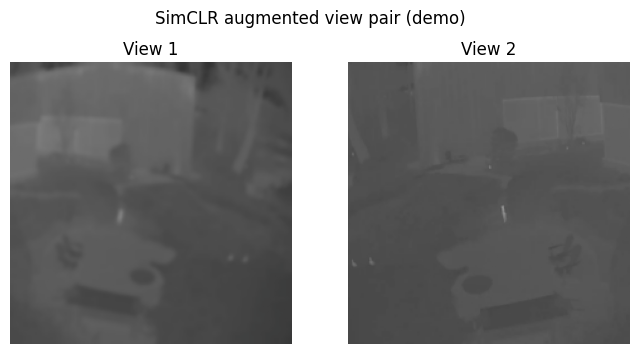

In [6]:
demo_v1, demo_v2 = train_dataset[0]
def denorm(t):
    mean = torch.tensor([0.485, 0.456, 0.406]).view(3,1,1)
    std = torch.tensor([0.229, 0.224, 0.225]).view(3,1,1)
    return (t * std + mean).clamp(0, 1).permute(1,2,0).numpy()
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(denorm(demo_v1)); axes[0].set_title('View 1'); axes[0].axis('off')
axes[1].imshow(denorm(demo_v2)); axes[1].set_title('View 2'); axes[1].axis('off')
plt.suptitle('SimCLR augmented view pair (demo)')
plt.show()

## 5. Model Definition — Encoder + Projection Head

In [7]:
class YOLOv12sBackboneEncoder(nn.Module):
    """
    Wraps the first `cutoff+1` layers of a yolo12s.yaml graph as a standalone encoder,
    re-implementing ultralytics' internal forward-graph walk (handles the skip/concat
    connections used by layers whose `.f` attribute is not -1), truncated at `cutoff`.
    Exists so this notebook's pretrained weights can be loaded key-for-key into the
    YOLOv12s backbone in Notebook *b's weight-surgery cell.
    """
    def __init__(self, num_classes=3, cutoff=9):
        super().__init__()
        base = YOLO('yolo12s.yaml').model
        base.nc = num_classes
        self.layers = base.model            # nn.Sequential, full graph (backbone+neck+head)
        self.save = set(base.save)           # indices whose outputs feed later layers
        self.cutoff = cutoff
        # probe output channel count at the cutoff layer with a dummy forward pass
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            feat = self._forward_backbone(dummy)
        self.out_channels = feat.shape[1]

    def _forward_backbone(self, x):
        y = []
        out = None
        for i, m in enumerate(self.layers):
            if i > self.cutoff:
                break
            if m.f != -1:
                x = y[m.f] if isinstance(m.f, int) else [x if j == -1 else y[j] for j in m.f]
            x = m(x)
            y.append(x if i in self.save else None)
            out = x
        return out

    def forward(self, x):
        return self._forward_backbone(x)      # returns the final backbone feature map (B, C, H, W)

    def pooled(self, x):
        feat = self.forward(x)
        return F.adaptive_avg_pool2d(feat, 1).flatten(1)   # (B, C)

    def backbone_state_dict(self):
        """State dict with keys prefixed to match YOLO('yolo12s.yaml').model.state_dict() keys
        exactly (e.g. 'model.0.conv.weight'), so Notebook *b's literal-key match succeeds."""
        sd = {}
        for k, v in self.layers.state_dict().items():
            layer_idx = int(k.split('.', 1)[0])
            if layer_idx <= self.cutoff:
                sd[f'model.{k}'] = v
        return sd

print('YOLOv12sBackboneEncoder defined.')

YOLOv12sBackboneEncoder defined.


In [8]:
class ProjectionHead(nn.Module):
    def __init__(self, in_dim, hidden_dim=512, out_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim), nn.ReLU(inplace=True), nn.Linear(hidden_dim, out_dim)
        )
    def forward(self, x):
        return self.net(x)

encoder = YOLOv12sBackboneEncoder(num_classes=NUM_CLASSES, cutoff=CONFIG['backbone_cutoff']).to(DEVICE)
proj_head = ProjectionHead(encoder.out_channels, out_dim=CONFIG['proj_dim']).to(DEVICE)
print('Encoder backbone output channels:', encoder.out_channels)

Encoder backbone output channels: 512


## 6. NT-Xent Loss

In [9]:
def nt_xent_loss(z1, z2, temperature):
    # Computed in float32 regardless of the surrounding autocast context: -1e9 used for
    # diagonal masking overflows fp16's range (~65504), which crashes GradScaler with a
    # 'value cannot be converted to type c10::Half' RuntimeError under mixed precision.
    B = z1.shape[0]
    z1, z2 = F.normalize(z1.float(), dim=1), F.normalize(z2.float(), dim=1)
    z = torch.cat([z1, z2], dim=0)                          # (2B, D)
    sim = torch.matmul(z, z.T) / temperature                # (2B, 2B), float32
    sim.fill_diagonal_(torch.finfo(sim.dtype).min)          # safe mask value for this dtype
    targets = torch.cat([torch.arange(B, 2*B), torch.arange(0, B)]).to(z.device)
    return F.cross_entropy(sim, targets)

## 7. Training Loop (30 epochs)

In [10]:
optimizer = torch.optim.AdamW(list(encoder.parameters()) + list(proj_head.parameters()),
                               lr=CONFIG['lr'], weight_decay=CONFIG['weight_decay'])
scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])

loss_history = []
for epoch in range(CONFIG['epochs']):
    encoder.train(); proj_head.train()
    running_loss = 0.0
    for v1, v2 in train_loader:
        v1, v2 = v1.to(DEVICE, non_blocking=True), v2.to(DEVICE, non_blocking=True)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast(enabled=CONFIG['amp']):
            z1 = proj_head(encoder.pooled(v1))
            z2 = proj_head(encoder.pooled(v2))
            loss = nt_xent_loss(z1, z2, CONFIG['temperature'])
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)
    print(f'Epoch {epoch+1}/{CONFIG["epochs"]} | NT-Xent loss: {epoch_loss:.4f}')

/tmp/ipykernel_23/2636545862.py:3: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=CONFIG['amp'])
/tmp/ipykernel_23/2636545862.py:12: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=CONFIG['amp']):


Epoch 1/30 | NT-Xent loss: 3.8039
Epoch 2/30 | NT-Xent loss: 3.4035
Epoch 3/30 | NT-Xent loss: 3.2700
Epoch 4/30 | NT-Xent loss: 3.1960
Epoch 5/30 | NT-Xent loss: 3.1614
Epoch 6/30 | NT-Xent loss: 3.1272
Epoch 7/30 | NT-Xent loss: 3.1084
Epoch 8/30 | NT-Xent loss: 3.0890
Epoch 9/30 | NT-Xent loss: 3.0731
Epoch 10/30 | NT-Xent loss: 3.0663
Epoch 11/30 | NT-Xent loss: 3.0577
Epoch 12/30 | NT-Xent loss: 3.0502
Epoch 13/30 | NT-Xent loss: 3.0451
Epoch 14/30 | NT-Xent loss: 3.0382
Epoch 15/30 | NT-Xent loss: 3.0317
Epoch 16/30 | NT-Xent loss: 3.0262
Epoch 17/30 | NT-Xent loss: 3.0236
Epoch 18/30 | NT-Xent loss: 3.0214
Epoch 19/30 | NT-Xent loss: 3.0160
Epoch 20/30 | NT-Xent loss: 3.0111
Epoch 21/30 | NT-Xent loss: 3.0081
Epoch 22/30 | NT-Xent loss: 3.0063
Epoch 23/30 | NT-Xent loss: 3.0023
Epoch 24/30 | NT-Xent loss: 3.0018
Epoch 25/30 | NT-Xent loss: 2.9989
Epoch 26/30 | NT-Xent loss: 2.9931
Epoch 27/30 | NT-Xent loss: 2.9932
Epoch 28/30 | NT-Xent loss: 2.9888
Epoch 29/30 | NT-Xent loss: 2

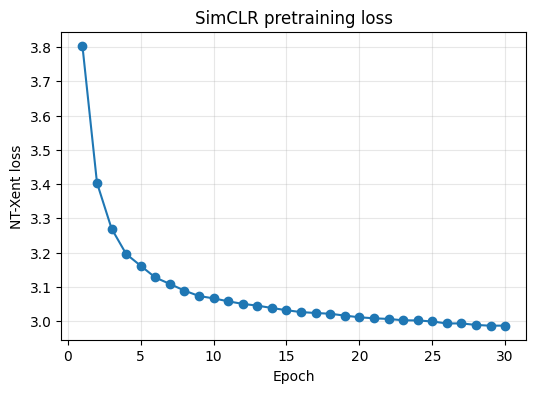

In [11]:
plt.figure(figsize=(6,4))
plt.plot(range(1, len(loss_history)+1), loss_history, marker='o')
plt.xlabel('Epoch'); plt.ylabel('NT-Xent loss'); plt.title('SimCLR pretraining loss')
plt.grid(alpha=0.3)
plt.savefig(CONFIG['work_dir'] / 'simclr_loss_curve.png', dpi=150)
plt.show()

## 8. Representation Diagnostics
Embeddings are extracted for a sample of **validation** images (labels are used only to color the plot for inspection — never for training).

Embeddings shape: (200, 512)


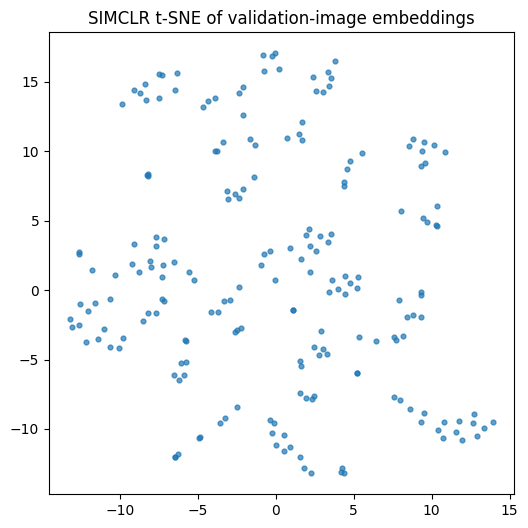

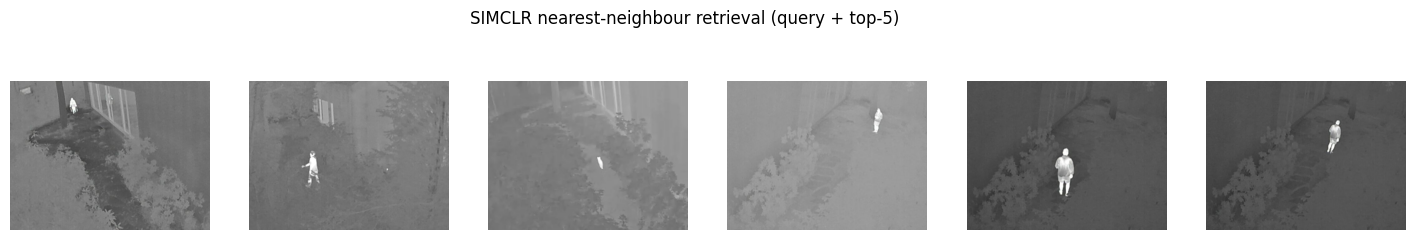

In [12]:
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

diag_transform = T.Compose([
    T.Resize((CONFIG['imgsz'], CONFIG['imgsz'])), T.ToTensor(),
    T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

sample_val = val_images_with_labels[:200] if len(val_images_with_labels) > 200 else val_images_with_labels
encoder.eval()
embeddings, img_paths_used = [], []
with torch.no_grad():
    for img_path, _ in sample_val:
        x = diag_transform(Image.open(img_path).convert('RGB')).unsqueeze(0).to(DEVICE)
        emb = encoder.pooled(x).squeeze(0).cpu().numpy()
        embeddings.append(emb); img_paths_used.append(img_path)
embeddings = np.stack(embeddings)
print('Embeddings shape:', embeddings.shape)

tsne = TSNE(n_components=2, random_state=CONFIG['seed'], perplexity=min(30, len(embeddings)-1))
emb_2d = tsne.fit_transform(embeddings)
plt.figure(figsize=(6,6)); plt.scatter(emb_2d[:,0], emb_2d[:,1], s=12, alpha=0.7)
plt.title('SIMCLR t-SNE of validation-image embeddings')
plt.savefig(CONFIG['work_dir'] / 'simclr_tsne.png', dpi=150); plt.show()

nn_model = NearestNeighbors(n_neighbors=6).fit(embeddings)
dists, idxs = nn_model.kneighbors(embeddings[0:1])
fig, axes = plt.subplots(1, 6, figsize=(18, 3))
for ax, i in zip(axes, idxs[0]):
    ax.imshow(Image.open(img_paths_used[i]).convert('RGB')); ax.axis('off')
plt.suptitle('SIMCLR nearest-neighbour retrieval (query + top-5)')
plt.savefig(CONFIG['work_dir'] / 'simclr_retrieval.png', dpi=150); plt.show()

# Comment (fill in after inspecting the plots above):
# Does the embedding space organise images by visually/semantically similar target-class content?

## 9. Checkpoint Export

In [13]:
ckpt_path = CONFIG['work_dir'] / 'simclr_backbone.pt'
torch.save({'state_dict': encoder.backbone_state_dict(), 'method': 'simclr',
            'config': CONFIG}, ckpt_path)
print('Saved', ckpt_path)
print('Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so the matching *b notebook can attach it as an input.')

Saved /kaggle/working/simclr_backbone.pt
Publish /kaggle/working as a Kaggle dataset (e.g. group-i-partb-ssl-checkpoints) so the matching *b notebook can attach it as an input.


## 10. Viva Prep — Notes to Fill In (SimCLR)

- Why does SimCLR need negatives while BYOL doesn't?
- Role of temperature τ in NT-Xent — behaviour at very small τ:
- Why the projection head is discarded before transfer to the detector:
- Effect of the (Kaggle T4-limited) batch size on the contrastive objective:
- Which augmentations helped vs. could hurt detection fine-tuning on this dataset:
- How embeddings changed between an early vs. final checkpoint (t-SNE/retrieval):